# Review cycles target (preliminary)

This notebook builds the **review cycles** target for the capstone from the City of San Diego DSD Reviews table.

- **Source:** `data/02_Data Mazen Abugharbieh/Activity_Tables/DSD_Reviews_2026-10-19.csv`
- **One raw row** = one review task: one discipline's review of one record in one cycle.
- **Output:** one row per (RECORD_ID, DISCIPLINE), with `n_cycles` (the highest cycle number reached) and `needs_resubmittal` (`n_cycles >= 2`).

> **All results here are preliminary.** The data is a raw, unvalidated extract from DSD and has not been checked against DSD's own reporting yet.

Steps:
1. Load
2. Quick data check
3. Clean
4. Build the target
5. Flag unfinished records
6. Explore the target
7. Save
8. Summary, decisions, and open questions

## 1. Load

The file is about 210 MB, so we load only the 17 columns we need with `usecols`. This keeps memory near 500 MB.

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

DATA_PATH = "../data/02_Data Mazen Abugharbieh/Activity_Tables/DSD_Reviews_2026-10-19.csv"
OUT_PATH = "../data/processed/review_cycles.csv"

# Only the columns we use; the extra ones (due dates, hours) are not needed for this target
COLUMNS = [
    "RECORD_ID", "RECORD_TYPE", "RECORD_STATUS", "PROCESSING_TYPE", "TASK_TYPE",
    "DISCIPLINE", "DISCIPLINE_CATEGORY", "REVIEW_TYPE", "TASK_METHOD_TYPE",
    "DISCIPLINE_CYCLE_NUMBER", "TASK_STATUS_BEGIN", "BEGIN_DATE", "TASK_STATUS_END",
    "END_DATE", "DAYS_IN_REVIEW", "ABANDONED_TASK", "PROJECT_SCOPE",
]

# low_memory=False so pandas reads each column in one pass and doesn't guess mixed types
reviews = pd.read_csv(DATA_PATH, usecols=COLUMNS, low_memory=False)
print(reviews.shape)

(438373, 17)


Next, the column types and the first few rows.

In [2]:
reviews.dtypes

RECORD_ID                   object
RECORD_TYPE                 object
RECORD_STATUS               object
PROCESSING_TYPE             object
TASK_TYPE                   object
DISCIPLINE                  object
DISCIPLINE_CATEGORY         object
REVIEW_TYPE                 object
TASK_METHOD_TYPE            object
DISCIPLINE_CYCLE_NUMBER      int64
TASK_STATUS_BEGIN           object
BEGIN_DATE                  object
TASK_STATUS_END             object
END_DATE                    object
DAYS_IN_REVIEW             float64
ABANDONED_TASK               int64
PROJECT_SCOPE               object
dtype: object

In [3]:
reviews.head()

,RECORD_ID,RECORD_TYPE,RECORD_STATUS,PROCESSING_TYPE,TASK_TYPE,DISCIPLINE,DISCIPLINE_CATEGORY,REVIEW_TYPE,TASK_METHOD_TYPE,DISCIPLINE_CYCLE_NUMBER,TASK_STATUS_BEGIN,BEGIN_DATE,TASK_STATUS_END,END_DATE,DAYS_IN_REVIEW,ABANDONED_TASK,PROJECT_SCOPE
0,AGR-0001283,Approval - Process - Agreement,Resubmitted,NaN,Review,Review,DSD Review,Plan Review,NaN,1,Resubmitted,2023-11-07 08:46:46.187,Signed Off,2023-09-13 15:40:54.433,-55.0,0,NaN
1,AGR-0002498,Approval - Process - Agreement,Issued,NaN,Review,Review,DSD Review,Plan Review,NaN,1,Resubmitted,2026-03-30 13:38:58.093,Signed Off,2024-11-12 13:15:01.490,-503.0,0,NaN
2,AGR-0002671,Approval - Process - Agreement,Issued,NaN,Review,Review,DSD Review,Plan Review,NaN,1,Resubmitted,2024-07-17 13:42:27.643,Signed Off,2024-05-30 10:52:24.327,-48.0,0,NaN
3,AGR-0002694,Approval - Process - Agreement,Invoice Paid,NaN,Review,Review,DSD Review,Plan Review,NaN,1,In Progress,2025-08-05 14:29:33.790,Signed Off,2024-11-13 13:05:45.733,-265.0,0,NaN
4,AGR-0003468,Approval - Process - Agreement,Issued,NaN,Review,Review,DSD Review,Plan Review,NaN,1,In Progress,2024-12-06 10:36:30.163,Signed Off,2024-12-06 10:47:39.697,0.0,0,NaN


Each row is one task. Most columns are text. The only numeric columns are `DISCIPLINE_CYCLE_NUMBER`, `DAYS_IN_REVIEW`, and `ABANDONED_TASK`.

The extract uses the text `"undefined"` for missing values. We count those first, then replace them with real missing values so `isna()` and `value_counts(dropna=False)` treat them correctly.

In [4]:
# Count "undefined" per column before replacing, so we know where it shows up
undefined_counts = (reviews == "undefined").sum()
print(undefined_counts[undefined_counts > 0])

reviews = reviews.replace("undefined", np.nan)

PROCESSING_TYPE        4
TASK_METHOD_TYPE    1025
dtype: int64


`"undefined"` appears in only two columns: `PROCESSING_TYPE` (4 rows) and `TASK_METHOD_TYPE` (1,025 rows). Both are now `NaN`.

Next we parse the dates to see what time span the data covers.

In [5]:
reviews["BEGIN_DATE"] = pd.to_datetime(reviews["BEGIN_DATE"])
reviews["END_DATE"] = pd.to_datetime(reviews["END_DATE"])

print("First task begins:", reviews["BEGIN_DATE"].min())
print("Last task begins: ", reviews["BEGIN_DATE"].max())
print("Unique records:   ", reviews["RECORD_ID"].nunique())
print("Unique disciplines:", reviews["DISCIPLINE"].nunique())

First task begins: 2023-01-03 06:54:59.323000
Last task begins:  2026-10-19 10:59:41.267000
Unique records:    84972
Unique disciplines: 89


The tasks begin between January 2023 and the extraction date, October 19, 2026. They cover about 85,000 records and 89 disciplines. Records submitted recently have had little time to go through resubmittals, which is why Step 5 flags unfinished records.

## 2. Quick data check

First, missing values per column after the `"undefined"` replacement.

In [6]:
missing = reviews.isna().sum()
missing_pct = (missing / len(reviews) * 100).round(2)
pd.DataFrame({"n_missing": missing, "pct_missing": missing_pct}).sort_values("n_missing", ascending=False)

,n_missing,pct_missing
TASK_METHOD_TYPE,31580,7.20
PROJECT_SCOPE,28207,6.43
PROCESSING_TYPE,24174,5.51
TASK_STATUS_END,9420,2.15
END_DATE,9420,2.15
DAYS_IN_REVIEW,9420,2.15
REVIEW_TYPE,2213,0.50
RECORD_STATUS,2,0.00
RECORD_TYPE,2,0.00
TASK_TYPE,0,0.00


The columns we need for the target (`RECORD_ID`, `DISCIPLINE`, `DISCIPLINE_CYCLE_NUMBER`) have no missing values.

- `PROCESSING_TYPE` is missing on about 5.5% of rows. We keep those rows and show "missing" as its own group later.
- `END_DATE`, `TASK_STATUS_END`, and `DAYS_IN_REVIEW` are missing on the same 9,420 rows. These are tasks that were never closed, and they don't affect the cycle count.

Next, row counts per `DISCIPLINE_CATEGORY`, because Steps 3b and 3d filter on it.

In [7]:
reviews["DISCIPLINE_CATEGORY"].value_counts(dropna=False)

DISCIPLINE_CATEGORY
DSD Review                    398366
Other City Department          31817
External Agency or Utility      5977
Workflow Step                   2213
Name: count, dtype: int64

About 91% of rows are **DSD Review**. The rest come from other City departments, external agencies or utilities, and 2,213 "Workflow Step" rows.

## 3. Clean

Each rule gets its own cell and prints the row count before and after. Each rule's effect is recorded in the Decisions table at the end.

### 3a. Drop duplicate keys (RECORD_ID, TASK_TYPE, DISCIPLINE_CYCLE_NUMBER)

The same task in the same cycle should appear only once. First we check whether the repeats are exact copies.

In [8]:
KEY = ["RECORD_ID", "TASK_TYPE", "DISCIPLINE_CYCLE_NUMBER"]

dup_rows = reviews[reviews.duplicated(KEY, keep=False)]
print("Rows that are extra copies of a key:", reviews.duplicated(KEY).sum())
print("Rows that are exact full-row copies:", reviews.duplicated().sum())

# Which columns actually differ within a duplicated key?
differs = dup_rows.groupby(KEY).nunique(dropna=False).gt(1).sum()
differs[differs > 0]

Rows that are extra copies of a key: 459


Rows that are exact full-row copies: 0


TASK_METHOD_TYPE      28
TASK_STATUS_BEGIN     21
BEGIN_DATE           416
TASK_STATUS_END      257
END_DATE             392
DAYS_IN_REVIEW       351
ABANDONED_TASK        77
dtype: int64

The 459 extra rows are **not** exact copies. Within each duplicated key, the begin and end dates differ, and sometimes so does `ABANDONED_TASK`. It looks like a task was opened twice, and often one copy was abandoned while the other was completed.

Since Step 3c drops abandoned tasks, we **sort non-abandoned rows first** before keeping one row per key. Otherwise we could keep the abandoned copy, then drop it in 3c and lose a real review. Which copy we keep doesn't change `n_cycles`, because every copy has the same cycle number.

In [9]:
n_before = len(reviews)

# Sort so the completed (non-abandoned) copy of a duplicate is the one we keep
reviews = reviews.sort_values("ABANDONED_TASK", kind="stable")
reviews = reviews.drop_duplicates(subset=KEY, keep="first")

n_after = len(reviews)
print(f"Before: {n_before:,}  After: {n_after:,}  Dropped: {n_before - n_after:,}")

Before: 438,373  After: 437,914  Dropped: 459


Exactly the 459 known duplicate rows were removed.

### 3b. Drop Workflow Step rows

Rows with `DISCIPLINE_CATEGORY == "Workflow Step"` are process steps like Inspections, CEQA, and Permit Issuance. They are not plan reviews, so their "cycle number" doesn't count resubmittals. Most of them are also abandoned.

In [10]:
print(reviews.loc[reviews["DISCIPLINE_CATEGORY"] == "Workflow Step", "DISCIPLINE"].value_counts().head())

DISCIPLINE
Inspections              1876
CEQA                      320
Permit Issuance            12
B-s+Impact Fees (599)       4
DSD-ProjectSetUp            1
Name: count, dtype: int64


In [11]:
n_before = len(reviews)

reviews = reviews[reviews["DISCIPLINE_CATEGORY"] != "Workflow Step"]

n_after = len(reviews)
print(f"Before: {n_before:,}  After: {n_after:,}  Dropped: {n_before - n_after:,}")

Before: 437,914  After: 435,701  Dropped: 2,213


2,213 rows were dropped. These are the same rows that are missing `REVIEW_TYPE`, which supports the idea that they aren't reviews.

### 3c. Drop abandoned tasks (ABANDONED_TASK == 1)

An abandoned task was opened but never closed, and the record moved on without it. It doesn't represent a completed round of review, so we drop it.

**Side effect to watch:** if a discipline's highest cycle was abandoned, dropping it lowers that discipline's `n_cycles` by one or more. If all of a discipline's tasks were abandoned, the (record, discipline) pair disappears. We measure both effects at the end of Step 3d, where the DSD filter has also been applied.

In [12]:
# Keep a copy from before this rule so we can measure its effect on the target later
before_abandoned_drop = reviews.copy()

n_before = len(reviews)

reviews = reviews[reviews["ABANDONED_TASK"] != 1]

n_after = len(reviews)
print(f"Before: {n_before:,}  After: {n_after:,}  Dropped: {n_before - n_after:,}")

Before: 435,701  After: 433,034  Dropped: 2,667


2,667 abandoned rows were dropped. That's fewer than the 4,829 total, because 3a and 3b already removed some abandoned rows (most Workflow Step rows were abandoned).

### 3d. Keep DSD Review disciplines only

**Why:** this project is about DSD's own plan review, which is the part of the process DSD controls and can change. Other City departments (such as Facilities Financing and Park & Recreation) and external agencies (such as Housing Commission, Community Planning Groups, Coastal Commission, and utilities) have their own staffing, timelines, and rules about what triggers a resubmittal. Their cycle counts measure a different process.

These are also only about 9% of rows. Mixing them in would mostly add noise.

In [13]:
n_before = len(reviews)

reviews = reviews[reviews["DISCIPLINE_CATEGORY"] == "DSD Review"]

n_after = len(reviews)
print(f"Before: {n_before:,}  After: {n_after:,}  Dropped: {n_before - n_after:,}")

Before: 433,034  After: 396,085  Dropped: 36,949


36,949 non-DSD rows were dropped. Note that `DSD-Historic` is categorized as an "Other City Department" in the raw data even though its name starts with "DSD". That makes it the largest discipline we drop. We should ask DSD about this (see open questions).

Now we can measure the side effect of 3c: we compare the target computed with and without abandoned tasks, both restricted to DSD Review.

In [14]:
GROUP = ["RECORD_ID", "DISCIPLINE"]

dsd_with_abandoned = before_abandoned_drop[before_abandoned_drop["DISCIPLINE_CATEGORY"] == "DSD Review"]
max_with = dsd_with_abandoned.groupby(GROUP)["DISCIPLINE_CYCLE_NUMBER"].max()
max_without = reviews.groupby(GROUP)["DISCIPLINE_CYCLE_NUMBER"].max()

pairs_lost = len(max_with) - len(max_without)
# Compare only the pairs that survive
pairs_lowered = (max_with.loc[max_without.index] != max_without).sum()

print(f"(record, discipline) pairs with abandoned tasks kept:    {len(max_with):,}")
print(f"(record, discipline) pairs with abandoned tasks dropped: {len(max_without):,}")
print(f"Pairs removed entirely: {pairs_lost:,}")
print(f"Pairs whose n_cycles went down: {pairs_lowered:,}")

del before_abandoned_drop, dsd_with_abandoned

(record, discipline) pairs with abandoned tasks kept:    202,866
(record, discipline) pairs with abandoned tasks dropped: 201,500
Pairs removed entirely: 1,366
Pairs whose n_cycles went down: 669


Dropping abandoned tasks removes 1,366 (record, discipline) pairs and lowers `n_cycles` for 669 more, out of about 202,900. That's under 1% of pairs in total. The effect is small, but the choice is a real one and goes in the Decisions table.

### 3e. Negative DAYS_IN_REVIEW: count but do not filter

Some tasks have an `END_DATE` before their `BEGIN_DATE`, which gives a negative `DAYS_IN_REVIEW`. We count them here but **keep them**.

In [15]:
negative_days = reviews["DAYS_IN_REVIEW"] < 0
print("Rows with negative DAYS_IN_REVIEW:", negative_days.sum())
print(reviews.loc[negative_days, "DAYS_IN_REVIEW"].describe().round(1))

Rows with negative DAYS_IN_REVIEW: 619
count    619.0
mean     -15.2
std       48.4
min     -530.0
25%       -7.0
50%       -3.0
75%       -1.0
max       -1.0
Name: DAYS_IN_REVIEW, dtype: float64


619 of the original 633 negative rows are still here. Most are off by only a few days (median −3), but a few are off by more than a year. That suggests the begin date was overwritten when a task was reopened.

**Why we don't filter them:** the target is the highest `DISCIPLINE_CYCLE_NUMBER`, which doesn't depend on any dates. A bad `BEGIN_DATE` doesn't mean the review cycle didn't happen, so dropping these rows could wrongly lower `n_cycles`. These rows only matter for duration targets such as days in review, and that analysis should handle them separately.

## 4. Build the target

We group by (RECORD_ID, DISCIPLINE) and take the highest `DISCIPLINE_CYCLE_NUMBER` as `n_cycles`. We use `DISCIPLINE` instead of `TASK_TYPE` because the raw data has a few duplicate task names like "Copy of DSD-Structural1", and `DISCIPLINE` already merges those into one name.

The record-level columns are carried along with `"first"`. Before relying on that, we check that they really are constant within each group.

In [16]:
KEEP_COLS = ["RECORD_TYPE", "PROCESSING_TYPE", "REVIEW_TYPE", "PROJECT_SCOPE", "RECORD_STATUS"]

# "first" is only safe if each column has one value per group
varying = reviews.groupby(GROUP)[KEEP_COLS].nunique().gt(1).sum()
print("Groups where the column takes more than one value:")
print(varying)

Groups where the column takes more than one value:
RECORD_TYPE        0
PROCESSING_TYPE    0
REVIEW_TYPE        0
PROJECT_SCOPE      0
RECORD_STATUS      0
dtype: int64


All five columns take a single value within every (record, discipline) group, so `"first"` loses nothing. We also keep `RECORD_STATUS` because Step 5 needs it.

In [17]:
cycles = (
    reviews
    .groupby(GROUP)
    .agg(
        n_cycles=("DISCIPLINE_CYCLE_NUMBER", "max"),
        n_cycle_rows=("DISCIPLINE_CYCLE_NUMBER", "nunique"),
        RECORD_TYPE=("RECORD_TYPE", "first"),
        PROCESSING_TYPE=("PROCESSING_TYPE", "first"),
        REVIEW_TYPE=("REVIEW_TYPE", "first"),
        PROJECT_SCOPE=("PROJECT_SCOPE", "first"),
        RECORD_STATUS=("RECORD_STATUS", "first"),
    )
    .reset_index()
)

cycles["needs_resubmittal"] = cycles["n_cycles"] >= 2

print(cycles.shape)
cycles.head()

(201500, 10)


,RECORD_ID,DISCIPLINE,n_cycles,n_cycle_rows,RECORD_TYPE,PROCESSING_TYPE,REVIEW_TYPE,PROJECT_SCOPE,RECORD_STATUS,needs_resubmittal
0,AGR-0001283,Review,1,1,Approval - Process - Agreement,None,Plan Review,None,Resubmitted,False
1,AGR-0002498,Review,1,1,Approval - Process - Agreement,None,Plan Review,None,Issued,False
2,AGR-0002671,Review,1,1,Approval - Process - Agreement,None,Plan Review,None,Issued,False
3,AGR-0002694,Review,1,1,Approval - Process - Agreement,None,Plan Review,None,Invoice Paid,False
4,AGR-0003468,Review,1,1,Approval - Process - Agreement,None,Plan Review,None,Issued,False


The table has 201,500 (record, discipline) pairs. We also kept `n_cycle_rows`, the number of distinct cycles actually present. If it's less than `n_cycles`, some cycle numbers are missing.

In [18]:
gaps = cycles["n_cycle_rows"] != cycles["n_cycles"]
print("Pairs with a gap in their cycle numbers:", gaps.sum())
cycles.loc[gaps, ["RECORD_ID", "DISCIPLINE", "n_cycles", "n_cycle_rows"]]

Pairs with a gap in their cycle numbers: 3


,RECORD_ID,DISCIPLINE,n_cycles,n_cycle_rows
49173,PRJ-1087706,DSD-Minor Right of Way,3,2
99333,PRJ-1114391,DSD-Structural,4,3
120847,PRJ-1124608,DSD-Structural,2,1


Only 3 pairs skip a cycle number. Since `n_cycles` uses the highest number, not a count of rows, a missing middle cycle doesn't change the target. We drop the helper column now.

In [19]:
cycles = cycles.drop(columns="n_cycle_rows")

## 5. Flag unfinished records

A record still in review hasn't reached its final cycle count. A pair at cycle 1 today may reach cycle 3 next month. If we treat those as final, the target will be biased low. We flag them with `is_finished` based on `RECORD_STATUS`.

**Caveat:** `RECORD_STATUS` is the status **at extraction (Oct 19, 2026)**, not at review time, and it describes the whole record, not one discipline. In this snapshot it tells us whether the record could still get more cycles.

First, every status value and how many pairs have it.

In [20]:
cycles["RECORD_STATUS"].value_counts(dropna=False)

RECORD_STATUS
Closed                          62150
Issued                          51654
Inspecting                      28228
Recheck Required                24998
Application Expired             10040
In Review                        7342
Cancelled                        5327
Issuance Checklist Requested     4209
Final Closed                     2488
Approved Upon Final Payment      1906
Reviews Complete                 1488
Resubmitted                       698
Review Phase Complete             258
Withdrawn                         155
Issuance Checklist Submitted      137
Ready for Issuance                125
Pending Invoice Payment           110
Agreement Processing               97
Updates Required                   28
Pending Conditions                 19
Hearing Scheduled                  16
Resubmittal Required               16
Opened                              7
Inspection Followup                 1
None                                1
Invoice Paid                        

We sort the statuses into four groups. The question for each one is: **can this record still get another review cycle?**

| Group | Statuses | `is_finished` | Why |
|---|---|---|---|
| Approved / post-review | Closed, Final Closed, Issued, Inspecting, Inspection Followup, Approved Upon Final Payment, Issuance Checklist Requested, Issuance Checklist Submitted, Ready for Issuance, Pending Invoice Payment, Invoice Paid, Reviews Complete, Review Phase Complete | True | Plan review is done; the record is in issuance, payment, inspection, or closed. |
| Ended without approval | Application Expired, Cancelled, Canceled, Withdrawn | True | The record stopped, so its cycle count can't change. It's final, but the record never reached approval. |
| Still in review | In Review, Recheck Required, Resubmitted, Resubmittal Required, Updates Required, Opened, Application Pending Payment | False | More cycles are possible or likely. |
| Unclear | Agreement Processing, Pending Conditions, Hearing Scheduled, missing | False | These are mostly late-stage discretionary steps where more review may still be needed. We treat them as unfinished to be safe. They add up to only about 130 pairs. |

Including "ended without approval" in finished is a deliberate choice. If we excluded them, we would drop records that may have expired *because* they needed many cycles, which would bias the resubmittal rate down. We check below whether the two finished groups look different.

In [21]:
FINISHED_APPROVED = [
    "Closed", "Final Closed", "Issued", "Inspecting", "Inspection Followup",
    "Approved Upon Final Payment", "Issuance Checklist Requested",
    "Issuance Checklist Submitted", "Ready for Issuance", "Pending Invoice Payment",
    "Invoice Paid", "Reviews Complete", "Review Phase Complete",
]
FINISHED_ENDED = ["Application Expired", "Cancelled", "Canceled", "Withdrawn"]
FINISHED_STATUSES = FINISHED_APPROVED + FINISHED_ENDED

cycles["is_finished"] = cycles["RECORD_STATUS"].isin(FINISHED_STATUSES)

# Every status not in the finished list (including missing) is treated as unfinished
print(cycles["is_finished"].value_counts())
print()
print("Statuses treated as unfinished:")
print(cycles.loc[~cycles["is_finished"], "RECORD_STATUS"].value_counts(dropna=False))

is_finished
True     168278
False     33222
Name: count, dtype: int64

Statuses treated as unfinished:
RECORD_STATUS
Recheck Required        24998
In Review                7342
Resubmitted               698
Agreement Processing       97
Updates Required           28
Pending Conditions         19
Hearing Scheduled          16
Resubmittal Required       16
Opened                      7
None                        1
Name: count, dtype: int64


About 83% of pairs are finished. Nearly all the unfinished pairs are "Recheck Required" or "In Review". No rows are dropped here; they are only flagged.

As a check, we compare resubmittal rates for approved records, records that ended without approval, and unfinished records.

In [22]:
status_group = np.where(
    cycles["RECORD_STATUS"].isin(FINISHED_APPROVED), "finished: approved",
    np.where(cycles["RECORD_STATUS"].isin(FINISHED_ENDED), "finished: ended without approval", "not finished"),
)

check = cycles.groupby(status_group).agg(
    n_pairs=("n_cycles", "size"),
    mean_cycles=("n_cycles", "mean"),
    resubmittal_rate=("needs_resubmittal", "mean"),
).round(3)
check

,n_pairs,mean_cycles,resubmittal_rate
finished: approved,152755,2.014,0.551
finished: ended without approval,15523,1.763,0.421
not finished,33222,1.838,0.466


- **Unfinished pairs have a lower rate (46.6%) than approved ones (55.1%).** This is what we'd expect if many are partway through and haven't gotten their later cycles yet. It confirms that leaving them in would bias the target down.
- **Records that ended without approval also have a lower rate (42.1%).** Their counts are final, but these records tend to stop early instead of after many rounds. Including them lowers the overall finished rate by about one point (53.9% vs. 55.1% for approved-only). Whether to keep them depends on the question we're asking, so it's listed as an open question.

## 6. Explore the target (finished records only)

From here on we use only `is_finished == True` pairs, so unfinished counts don't pull the numbers down.

In [23]:
finished = cycles[cycles["is_finished"]]
print(f"Finished pairs: {len(finished):,} of {len(cycles):,}")

Finished pairs: 168,278 of 201,500


### 6a. Distribution of n_cycles

In [24]:
cycle_counts = finished["n_cycles"].value_counts().sort_index()
cycle_share = (cycle_counts / cycle_counts.sum() * 100).round(1)
pd.DataFrame({"n_pairs": cycle_counts, "pct": cycle_share})

,n_pairs,pct
n_cycles,,
1,77647,46.1
2,47100,28.0
3,24242,14.4
4,11121,6.6
5,4967,3.0
6,2003,1.2
7,724,0.4
8,318,0.2
9,100,0.1


The bar chart below shows the same counts. The y-axis is linear, so the long tail (7+ cycles) is barely visible. The table above has the exact numbers.

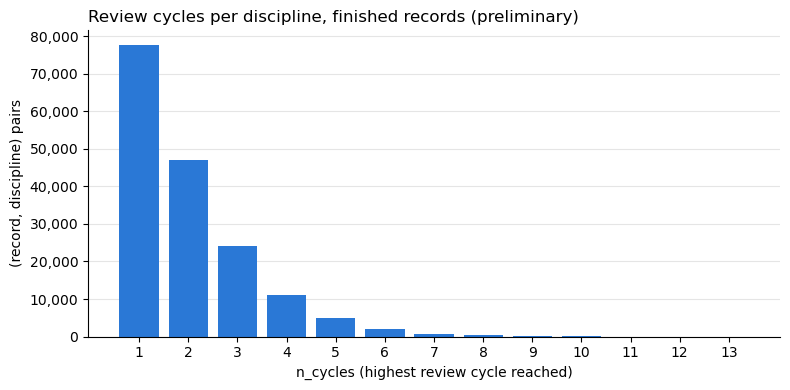

In [25]:
BAR_COLOR = "#2a78d6"

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(cycle_counts.index, cycle_counts.values, color=BAR_COLOR, width=0.8)
ax.set_xticks(cycle_counts.index)
ax.set_xlabel("n_cycles (highest review cycle reached)")
ax.set_ylabel("(record, discipline) pairs")
ax.set_title("Review cycles per discipline, finished records (preliminary)", loc="left")
# Keep gridlines and frame quiet so the bars carry the reading
ax.yaxis.grid(True, color="#e5e5e5")
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
plt.tight_layout()
plt.show()

46% of finished pairs are approved on the first review, and 28% need exactly one resubmittal. The distribution is strongly right-skewed: about 5% reach 5 or more cycles, and fewer than 0.3% go past 8. For modeling, this suggests either the binary flag or a capped count (for example "5+"), so the rare 10–13 cycle cases don't dominate.

### 6b. needs_resubmittal rate overall

In [26]:
overall_rate = finished["needs_resubmittal"].mean()
print(f"Share of finished (record, discipline) pairs needing at least one resubmittal: {overall_rate:.1%}")

Share of finished (record, discipline) pairs needing at least one resubmittal: 53.9%


Just over half (53.9%) of discipline reviews on finished records need at least one resubmittal. For a classification target, that's a nearly balanced split, so we won't need special handling for a rare class.

### 6c. needs_resubmittal rate by DISCIPLINE (top 15 by volume)

We pick the 15 disciplines with the most finished pairs so each rate is based on thousands of pairs, not a handful.

In [27]:
by_discipline = finished.groupby("DISCIPLINE").agg(
    n_pairs=("needs_resubmittal", "size"),
    resubmittal_rate=("needs_resubmittal", "mean"),
    mean_cycles=("n_cycles", "mean"),
)
top15 = by_discipline.sort_values("n_pairs", ascending=False).head(15)
top15.sort_values("resubmittal_rate", ascending=False).round(3)

,n_pairs,resubmittal_rate,mean_cycles
DISCIPLINE,,,
DSD-Minor Right of Way,3085,0.914,3.405
DSD-Engineering Building Review,12488,0.745,2.414
DSD-Right of Way Dry Utilities,7460,0.738,2.126
DSD-Water and Sewer,3397,0.732,2.682
DSD-Structural,19582,0.708,2.343
DSD-Addressing,5157,0.664,1.906
DSD-HazMat,2881,0.646,2.009
DSD-Combined,17204,0.619,2.092
DSD-Mechanical,6976,0.586,2.147


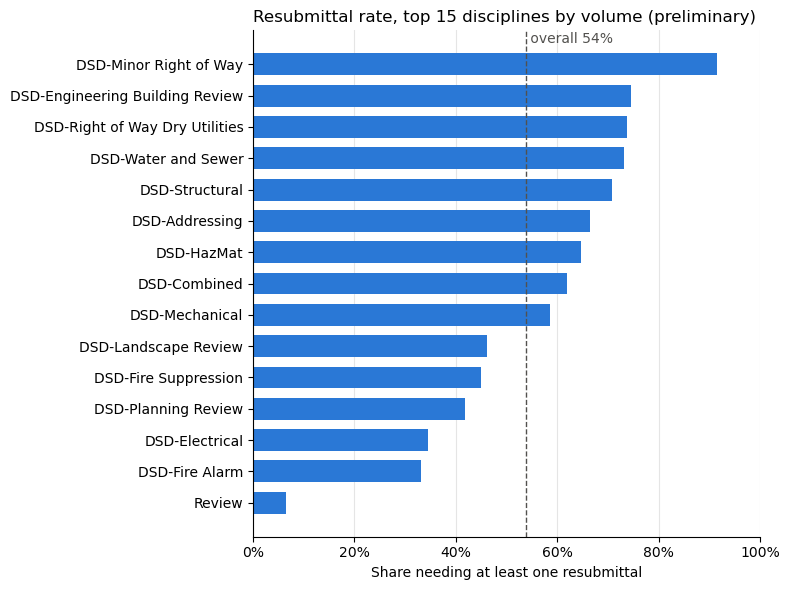

In [28]:
plot_data = top15.sort_values("resubmittal_rate")

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(plot_data.index, plot_data["resubmittal_rate"], color=BAR_COLOR, height=0.7)
ax.axvline(overall_rate, color="#52514e", linestyle="--", linewidth=1)
ax.text(overall_rate, len(plot_data) - 0.4, f" overall {overall_rate:.0%}", color="#52514e", va="bottom")
ax.set_xlim(0, 1)
ax.set_xlabel("Share needing at least one resubmittal")
ax.set_title("Resubmittal rate, top 15 disciplines by volume (preliminary)", loc="left")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.xaxis.grid(True, color="#e5e5e5")
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

Discipline matters a lot.
- **DSD-Minor Right of Way** almost always needs a resubmittal (91%, averaging 3.4 cycles).
- **Engineering Building Review, Right of Way Dry Utilities, Water and Sewer, and Structural** are all around 70–75%.
- **Electrical and Fire Alarm** are around one in three.
- **The generic "Review" discipline** is at 6.5%. It belongs to simple permits (Construction Noise Permits, Zone History Letters, Transportation Permits) that get one sign-off rather than a full plan review.

Keep in mind that each record contributes one pair per discipline, so records reviewed by many disciplines count many times.

### 6d. needs_resubmittal rate by PROCESSING_TYPE

Missing `PROCESSING_TYPE` is shown as its own group so those pairs aren't silently dropped.

In [29]:
by_processing = finished.groupby("PROCESSING_TYPE", dropna=False).agg(
    n_pairs=("needs_resubmittal", "size"),
    resubmittal_rate=("needs_resubmittal", "mean"),
    mean_cycles=("n_cycles", "mean"),
)
by_processing.sort_values("n_pairs", ascending=False).round(3)

,n_pairs,resubmittal_rate,mean_cycles
PROCESSING_TYPE,,,
Standard,112245,0.543,1.984
Express,39011,0.624,2.205
NaN,15037,0.265,1.395
Expedite,1985,0.714,2.683


At first glance, faster tracks have *more* resubmittals: Expedite 71%, Express 62%, Standard 54%. Missing `PROCESSING_TYPE` is lowest at 27%, because it's mostly record types without a processing track, such as Deferred Fire Submittals, noise permits, and zone history letters.

The Express vs. Standard gap may come from which record types use each track, not from the track itself. We check this by comparing the two within each record type that offers both.

In [30]:
# Compare Express vs Standard inside the same RECORD_TYPE to remove the record-type mix
both_tracks = finished[finished["PROCESSING_TYPE"].isin(["Express", "Standard"])]
within = both_tracks.pivot_table(
    index="RECORD_TYPE", columns="PROCESSING_TYPE",
    values="needs_resubmittal", aggfunc="mean",
)
counts = both_tracks.pivot_table(
    index="RECORD_TYPE", columns="PROCESSING_TYPE",
    values="needs_resubmittal", aggfunc="size",
)

# Only record types with at least 500 pairs on each track, so the rates are stable
enough = (counts["Express"] >= 500) & (counts["Standard"] >= 500)
within[enough].round(3)

PROCESSING_TYPE,Express,Standard
RECORD_TYPE,,
Building Construction,0.652,0.652
Building Construction Change,0.394,0.350
Engineering Construction Change,0.650,0.691
Fire,0.611,0.388
"Grading, ROW, Mapping - Standalone",0.796,0.773
Plan - Mechanical/Electrical/Plumbing Standalone,0.656,0.659
Right of Way - Dry Utilities,0.720,0.693


Within the same record type, Express and Standard rates are mostly almost the same. For Building Construction, both are 65.2%, and five other types differ by 4 points or less, in both directions. The one exception is **Fire**, where Express is 61% and Standard is 39%; that's worth asking DSD about. The raw gap comes mostly from Standard including Photovoltaic and Preliminary Review records, which are almost never resubmitted (both under 5%). **Processing type alone is not evidence that faster tracks cause more resubmittals.** Any model should control for `RECORD_TYPE`.

## 7. Save

We save the full table, including unfinished pairs with `is_finished == False`, so later notebooks can choose how to handle them. `RECORD_STATUS` is kept so the finished rule can be revisited.

In [31]:
# Create the folder if it's missing so the notebook runs on a fresh clone
os.makedirs(os.path.dirname(OUT_PATH), exist_ok=True)

output_cols = [
    "RECORD_ID", "DISCIPLINE", "n_cycles", "needs_resubmittal", "is_finished",
    "RECORD_STATUS", "RECORD_TYPE", "PROCESSING_TYPE", "REVIEW_TYPE", "PROJECT_SCOPE",
]
cycles[output_cols].to_csv(OUT_PATH, index=False)

print(f"Saved {len(cycles):,} rows x {len(output_cols)} columns to {OUT_PATH}")

Saved 201,500 rows x 10 columns to ../data/processed/review_cycles.csv


## 8. Summary (preliminary)

**What we built.** `data/processed/review_cycles.csv` has 201,500 rows, one per (RECORD_ID, DISCIPLINE), covering DSD Review disciplines on records with tasks from January 2023 to October 2026. Its columns are `n_cycles`, `needs_resubmittal`, `is_finished`, and record context (`RECORD_STATUS`, `RECORD_TYPE`, `PROCESSING_TYPE`, `REVIEW_TYPE`, `PROJECT_SCOPE`).

**Findings (finished records only, 168,278 pairs):**
- 53.9% of discipline reviews need at least one resubmittal. 46% are approved in one cycle, and about 5% take 5 or more.
- Discipline is the biggest driver we've seen so far. Rates range from 91% for Minor Right of Way, to about 70–75% for engineering, structural, utilities, and water/sewer, to about 33% for Electrical and Fire Alarm.
- The raw rate by processing type (Expedite > Express > Standard) is mostly explained by record type. Within the same record type, Express and Standard are nearly identical, except for Fire records (61% vs. 39%).
- Unfinished pairs (17% of the table) have lower rates than finished ones, as expected for records partway through review. Excluding them avoids biasing the target down.

**Cleaning choices** (details and row counts are in the Decisions table below):
- Removed duplicate tasks, keeping the completed copy.
- Removed Workflow Step rows, abandoned tasks, and non-DSD disciplines.
- Kept negative-duration rows, because the cycle target doesn't use dates.
- Flagged unfinished records instead of dropping them.

**Open questions for the DSD team:**
1. **Cycle numbering:** does `DISCIPLINE_CYCLE_NUMBER` go up only when *that discipline* asks for corrections, or does every discipline get a new cycle whenever the record is resubmitted? This decides whether `n_cycles` measures that discipline's own outcome.
2. **Abandoned tasks:** when a discipline's highest cycle was abandoned, did the applicant actually resubmit? Should that cycle count? (It affects 669 pairs, plus 1,366 pairs that disappear.)
3. **Duplicate tasks:** why are 459 tasks opened twice for the same cycle? Is the later copy the official one?
4. **DSD-Historic** is labeled "Other City Department". Is it DSD's own review, and should it be in the target?
5. **Finished status:** is there a reliable discipline-level "done" signal (for example, a final Signed Off task), or a status history, so we don't have to rely on the record's status at extraction?
6. **Unclear statuses:** can records in Agreement Processing, Pending Conditions, or Hearing Scheduled still get more review cycles?
7. **Ended without approval:** should expired, cancelled, and withdrawn records count toward the resubmittal rate, or be studied separately?
8. **Negative DAYS_IN_REVIEW:** is `BEGIN_DATE` overwritten when a task is reopened? This matters for any duration target.
9. **The generic "Review" discipline and missing `PROCESSING_TYPE`:** are these simple permits outside the scope of plan review? Should they be left out of modeling?
10. **Fire records on Express:** why do they need resubmittals so much more often than Fire records on Standard (61% vs. 39%)?

## Decisions

| # | Decision | Reason | Rows affected |
|---|---|---|---|
| 1 | Load only the 17 listed columns (`usecols`) | The full file is 210 MB; the other columns aren't needed for this target | Columns only; all 438,373 rows loaded |
| 2 | Treat `"undefined"` as missing | It's the extract's placeholder for no value | 1,029 values (4 in `PROCESSING_TYPE`, 1,025 in `TASK_METHOD_TYPE`); 0 rows dropped |
| 3a | Drop duplicate (RECORD_ID, TASK_TYPE, DISCIPLINE_CYCLE_NUMBER), keeping the non-abandoned copy | The same task in the same cycle should appear once; the copies differ only in dates and abandoned status, and the cycle number is the same | −459 rows (438,373 → 437,914) |
| 3b | Drop `DISCIPLINE_CATEGORY == "Workflow Step"` | Process steps (Inspections, CEQA, Permit Issuance), not plan reviews | −2,213 rows (→ 435,701) |
| 3c | Drop `ABANDONED_TASK == 1` | Never closed, so not a completed round of review | −2,667 rows (→ 433,034); removes 1,366 pairs and lowers `n_cycles` for 669 pairs |
| 3d | Keep `DISCIPLINE_CATEGORY == "DSD Review"` only | The target is about DSD's own review process; other departments and agencies run on separate processes | −36,949 rows (→ 396,085) |
| 3e | Keep negative `DAYS_IN_REVIEW` | The cycle target doesn't use dates; dropping them could wrongly lower `n_cycles` | 619 rows kept |
| 4a | Group by `DISCIPLINE`, not `TASK_TYPE` | `DISCIPLINE` merges "Copy of …" task-name variants | 396,085 rows → 201,500 pairs |
| 4b | `n_cycles` = highest cycle number, not a count of rows | Robust to missing middle cycles | 3 pairs with gaps get the correct value |
| 4c | Carry record columns with `"first"` | Checked to be constant within every pair | 0 conflicts |
| 5a | `is_finished` from `RECORD_STATUS` (approved/post-review and ended-without-approval = finished) | Their cycle counts can no longer change | 168,278 finished pairs (152,755 approved + 15,523 ended) |
| 5b | In-review and unclear statuses = not finished; flagged, not dropped | More cycles are possible; to be safe, unclear statuses count as unfinished | 33,222 unfinished pairs (133 of them unclear or missing status) |
| 6 | Explore finished pairs only | Avoids the downward bias from records partway through review | 168,278 pairs used in Step 6 |
| 7 | Save all pairs, including unfinished | Lets later notebooks choose how to handle them | 201,500 rows written |